# Experiment 8 — Classification Models (House Price Dataset)

**Covers:** Logistic Regression, KNN, Gaussian Naïve Bayes, accuracy, precision, recall, F1, AUC, odds ratios, confusion matrices, classification reports, ROC curves, KNN hyperparameter analysis and CSV results.

**Dataset:** **House Price – California Housing** – `housing.csv` from Kaggle ([camnugent/california-housing-prices](https://www.kaggle.com/datasets/camnugent/california-housing-prices)), 20,640 districts, target `median_house_value`, plus income, house age, rooms, population, location and `ocean_proximity`.

**Data file:** keep `housing.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\housing.csv")`).

**Remember:** Split → Three models → fit/predict/probability → Metrics → ROC → Odds → K values → Compare.

**Binary target:** house value is a number, so it is turned into two balanced classes (above / below the median value).

## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

df = pd.read_csv("housing.csv")

## 1. Prepare data

In [2]:
# Binary target: 1 = Expensive (house value above the median), 0 = Not expensive
cols = ["median_income", "housing_median_age", "total_rooms", "total_bedrooms",
        "population", "households", "latitude", "longitude"]
data = df.dropna()

X = data[cols]
y = (data["median_house_value"] > data["median_house_value"].median()).astype(int)

print("Class mapping: 0 = Not expensive, 1 = Expensive")
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", len(X_train), "Test:", len(X_test))

Class mapping: 0 = Not expensive, 1 = Expensive
median_house_value
0    10217
1    10216
Name: count, dtype: int64
Train: 16346 Test: 4087


## 2. Models (same loop for all three)


 Logistic
              precision    recall  f1-score   support

           0       0.84      0.84      0.84      2044
           1       0.84      0.84      0.84      2043

    accuracy                           0.84      4087
   macro avg       0.84      0.84      0.84      4087
weighted avg       0.84      0.84      0.84      4087



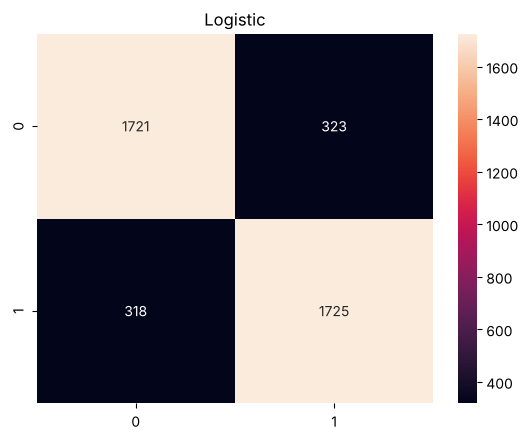


 KNN
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      2044
           1       0.85      0.85      0.85      2043

    accuracy                           0.85      4087
   macro avg       0.85      0.85      0.85      4087
weighted avg       0.85      0.85      0.85      4087



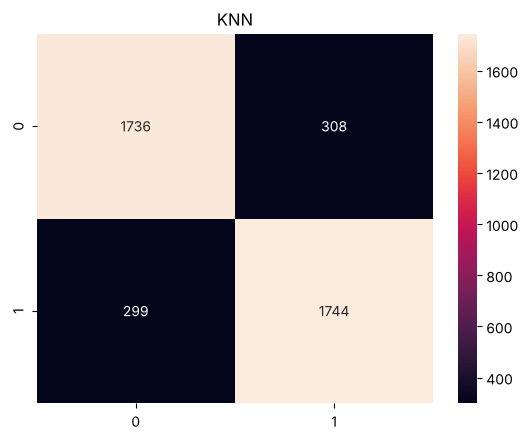


 Naive Bayes
              precision    recall  f1-score   support

           0       0.68      0.86      0.76      2044
           1       0.81      0.60      0.69      2043

    accuracy                           0.73      4087
   macro avg       0.75      0.73      0.73      4087
weighted avg       0.75      0.73      0.73      4087



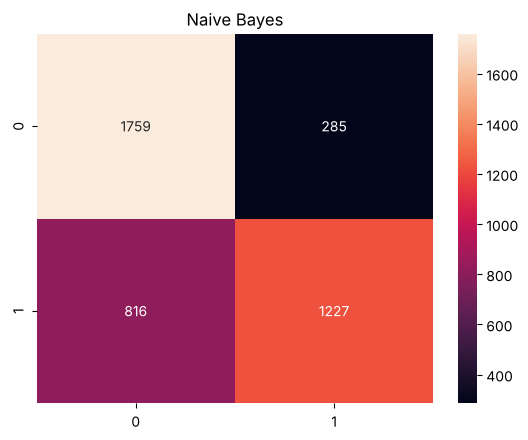

In [3]:
models = {
    "Logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Naive Bayes": make_pipeline(StandardScaler(), GaussianNB())
}

results = []
roc = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    results.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred),
        roc_auc_score(y_test, prob)
    ])

    print("\n", name)
    print(classification_report(y_test, pred))

    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d")
    plt.title(name)
    plt.show()

    fpr, tpr, _ = roc_curve(y_test, prob)
    roc[name] = (fpr, tpr)

## 3. ROC curves

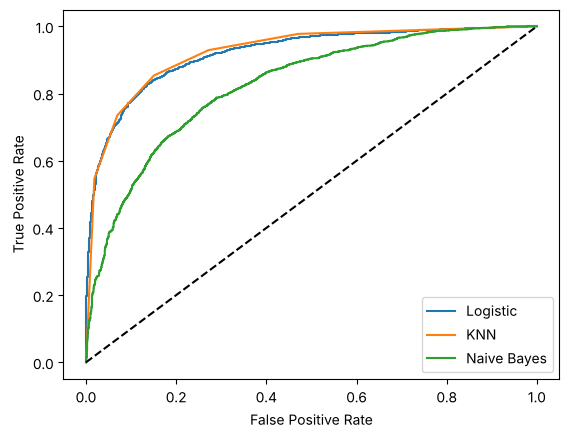

In [4]:
for name, (fpr, tpr) in roc.items():
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

## 4. Logistic regression coefficients and odds ratio

In [5]:
coef = models["Logistic"].named_steps["logisticregression"].coef_[0]
odds = pd.DataFrame({
    "Coefficient": coef,
    "Odds Ratio": np.exp(coef)
}, index=cols)
print(odds)

                    Coefficient  Odds Ratio
median_income          2.352324   10.509964
housing_median_age     0.323057    1.381345
total_rooms           -0.649113    0.522509
total_bedrooms         1.098984    3.001116
population            -1.507259    0.221516
households             1.194565    3.302122
latitude              -3.649145    0.026013
longitude             -3.372426    0.034306


## 5. Effect of K (5-fold CV)

    K  Accuracy        F1       AUC
0   1  0.813594  0.813525  0.813594
1   3  0.834271  0.834631  0.894122
2   5  0.839777  0.839727  0.911228
3   7  0.842958  0.842906  0.918893
4   9  0.843570  0.843716  0.921818
5  11  0.843265  0.843415  0.923851
6  15  0.841674  0.842038  0.924997
Best K: 15


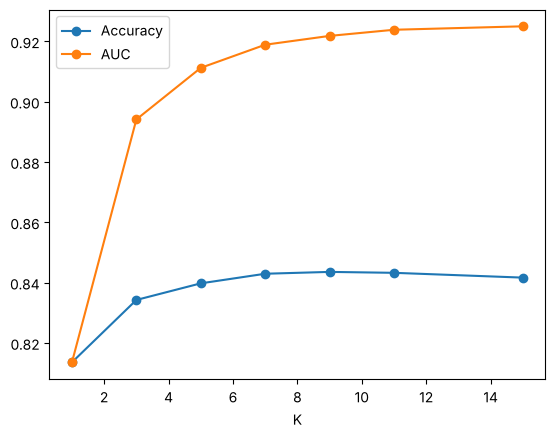

In [6]:
rows = []
for k in [1, 3, 5, 7, 9, 11, 15]:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv = cross_validate(model, X_train, y_train, cv=5,
                        scoring=["accuracy", "f1", "roc_auc"])
    rows.append([k, cv["test_accuracy"].mean(),
                 cv["test_f1"].mean(), cv["test_roc_auc"].mean()])

knn = pd.DataFrame(rows, columns=["K", "Accuracy", "F1", "AUC"])
print(knn)
print("Best K:", knn.loc[knn["AUC"].idxmax(), "K"])

knn.plot(x="K", y=["Accuracy", "AUC"], marker="o")
plt.show()

## 6. Comparison and save

             Accuracy  Precision    Recall        F1       AUC
Model                                                         
Logistic     0.843161   0.842285  0.844347  0.843315  0.919177
KNN          0.851480   0.849903  0.853647  0.851770  0.923129
Naive Bayes  0.730609   0.811508  0.600587  0.690295  0.824806


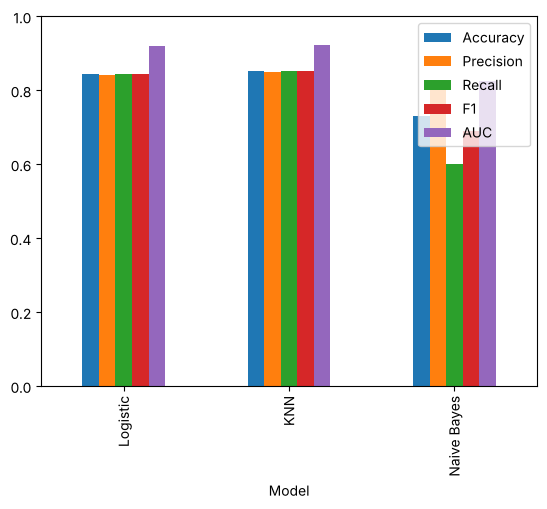

Saved classification.csv, logistic_coefficients.csv, knn_results.csv


In [7]:
result = pd.DataFrame(results, columns=[
    "Model", "Accuracy", "Precision", "Recall", "F1", "AUC"
]).set_index("Model")

print(result)
result.plot(kind="bar", ylim=(0, 1))
plt.show()

result.to_csv("classification.csv")
odds.to_csv("logistic_coefficients.csv")
knn.to_csv("knn_results.csv", index=False)
print("Saved classification.csv, logistic_coefficients.csv, knn_results.csv")

## Result / Conclusion
- Target: expensive (above median value) vs not; 16,346 train / 4,087 test districts, perfectly balanced.
- **KNN is best:** accuracy 0.851, AUC 0.923, ahead of Logistic Regression (0.843, AUC 0.919).
- **Naive Bayes is clearly worst** (accuracy 0.731, recall 0.60), because its assumption of independent, normally distributed features is violated (the size columns are strongly correlated and skewed).
- Odds ratios: income has the largest positive effect (OR 10.5 per SD); latitude and longitude have large negative coefficients, meaning location strongly affects price.